<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Histogram**


Estimated time needed: **45** minutes


In this lab, you will focus on the visualization of data. The dataset will be provided through an RDBMS, and you will need to use SQL queries to extract the required data.


## Objectives


In this lab, you will perform the following:


- Visualize the distribution of data using histograms.

- Visualize relationships between features.

- Explore data composition and comparisons.


## Demo: Working with database


#### Download the database file.


In [2]:
!wget -O survey-data.sqlite https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/QR9YeprUYhOoLafzlLspAw/survey-results-public.sqlite

Resolving cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)... 169.63.118.104
Connecting to cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud (cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud)|169.63.118.104|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 211415040 (202M) [application/octet-stream]
Saving to: ‘survey-data.sqlite’

survey-data.sqlite  100%[===================>] 201.62M  2.04MB/s    in 59s     

2026-10-11 22:42:07 (3.42 MB/s) - ‘survey-data.sqlite’ saved [211415040/211415040]


#### Install the required libraries and import them


In [1]:
!pip install pandas

In [3]:
!pip install matplotlib

In [4]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

#### Connect to the SQLite database


In [5]:
conn = sqlite3.connect('survey-data.sqlite')

## Demo: Basic SQL queries

**Demo 1: Count the number of rows in the table**


In [6]:
QUERY = "SELECT COUNT(*) FROM main"
df = pd.read_sql_query(QUERY, conn)
print(df)


   COUNT(*)
0     65437

**Demo 2: List all tables**


In [7]:
QUERY = """
SELECT name as Table_Name 
FROM sqlite_master 
WHERE type = 'table'
"""
pd.read_sql_query(QUERY, conn)


,Table_Name
0,main


**Demo 3: Group data by age**


In [8]:
QUERY = """
SELECT Age, COUNT(*) as count 
FROM main 
GROUP BY Age 
ORDER BY Age
"""
df_age = pd.read_sql_query(QUERY, conn)
print(df_age)

                  Age  count
0     18-24 years old  14098
1     25-34 years old  23911
2     35-44 years old  14942
3     45-54 years old   6249
4     55-64 years old   2575
5   65 years or older    772
6   Prefer not to say    322
7  Under 18 years old   2568

## Hands-on Lab: Visualizing Data with Histograms


### 1. Visualizing the distribution of data (Histograms)


**1.1 Histogram of `CompTotal` (Total Compensation)**


Objective: Plot a histogram of `CompTotal` to visualize the distribution of respondents' total compensation.


count     3.374000e+04
mean     2.963841e+145
std      5.444117e+147
min       0.000000e+00
25%       6.000000e+04
50%       1.100000e+05
75%       2.500000e+05
max      1.000000e+150
Name: CompTotal, dtype: float64

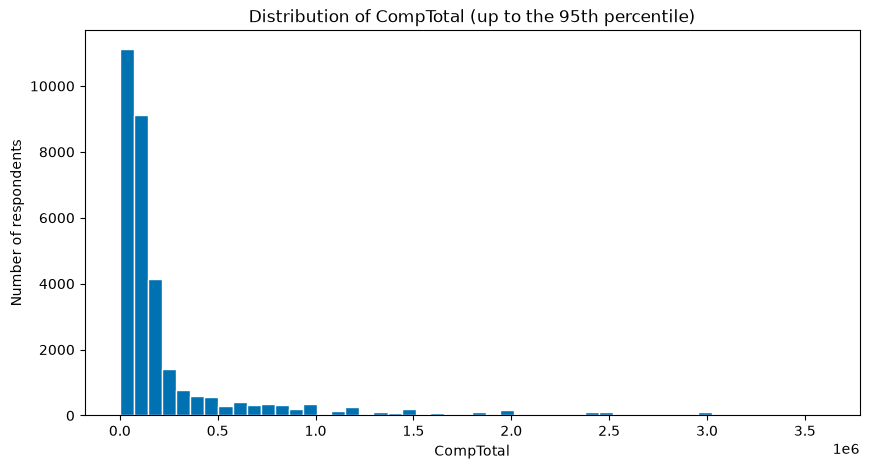

In [10]:
## Write your code here
## Write your code here
comp = pd.read_sql_query("SELECT CompTotal FROM main WHERE CompTotal IS NOT NULL", conn)["CompTotal"]
print(comp.describe())

# CompTotal has extreme values (some are clearly entry errors), so cap the view at the 95th percentile
cap = comp.quantile(0.95)
plt.figure(figsize=(10, 5))
plt.hist(comp[comp <= cap], bins=50, color="#0072B2", edgecolor="white")
plt.title("Distribution of CompTotal (up to the 95th percentile)")
plt.xlabel("CompTotal")
plt.ylabel("Number of respondents")
plt.show()

**1.2 Histogram of YearsCodePro (Years of Professional Coding Experience)**


Objective: Plot a histogram of `YearsCodePro` to analyze the distribution of coding experience among respondents.


count    51610.000000
mean        10.211044
std          9.075136
min          0.500000
25%          3.000000
50%          7.000000
75%         15.000000
max         50.000000
Name: YearsCodePro, dtype: float64

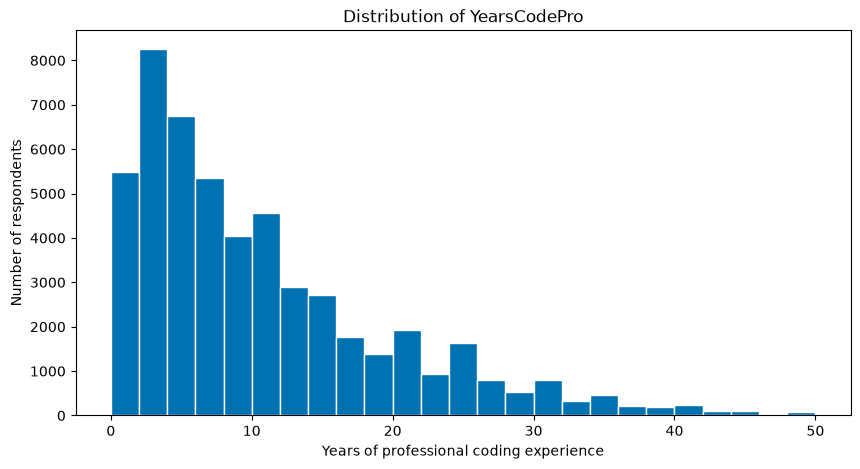

In [11]:
## Write your code here
## Write your code here
years = pd.read_sql_query("SELECT YearsCodePro FROM main WHERE YearsCodePro IS NOT NULL", conn)["YearsCodePro"]

# YearsCodePro is stored as text, so convert it to numbers first
years = years.replace({"Less than 1 year": 0.5, "More than 50 years": 50})
years = pd.to_numeric(years, errors="coerce").dropna()
print(years.describe())

plt.figure(figsize=(10, 5))
plt.hist(years, bins=range(0, 52, 2), color="#0072B2", edgecolor="white")
plt.title("Distribution of YearsCodePro")
plt.xlabel("Years of professional coding experience")
plt.ylabel("Number of respondents")
plt.show()

### 2. Visualizing Relationships in Data


**2.1 Histogram Comparison of `CompTotal` by `Age` Group**


Objective: Use histograms to compare the distribution of CompTotal across different Age groups.


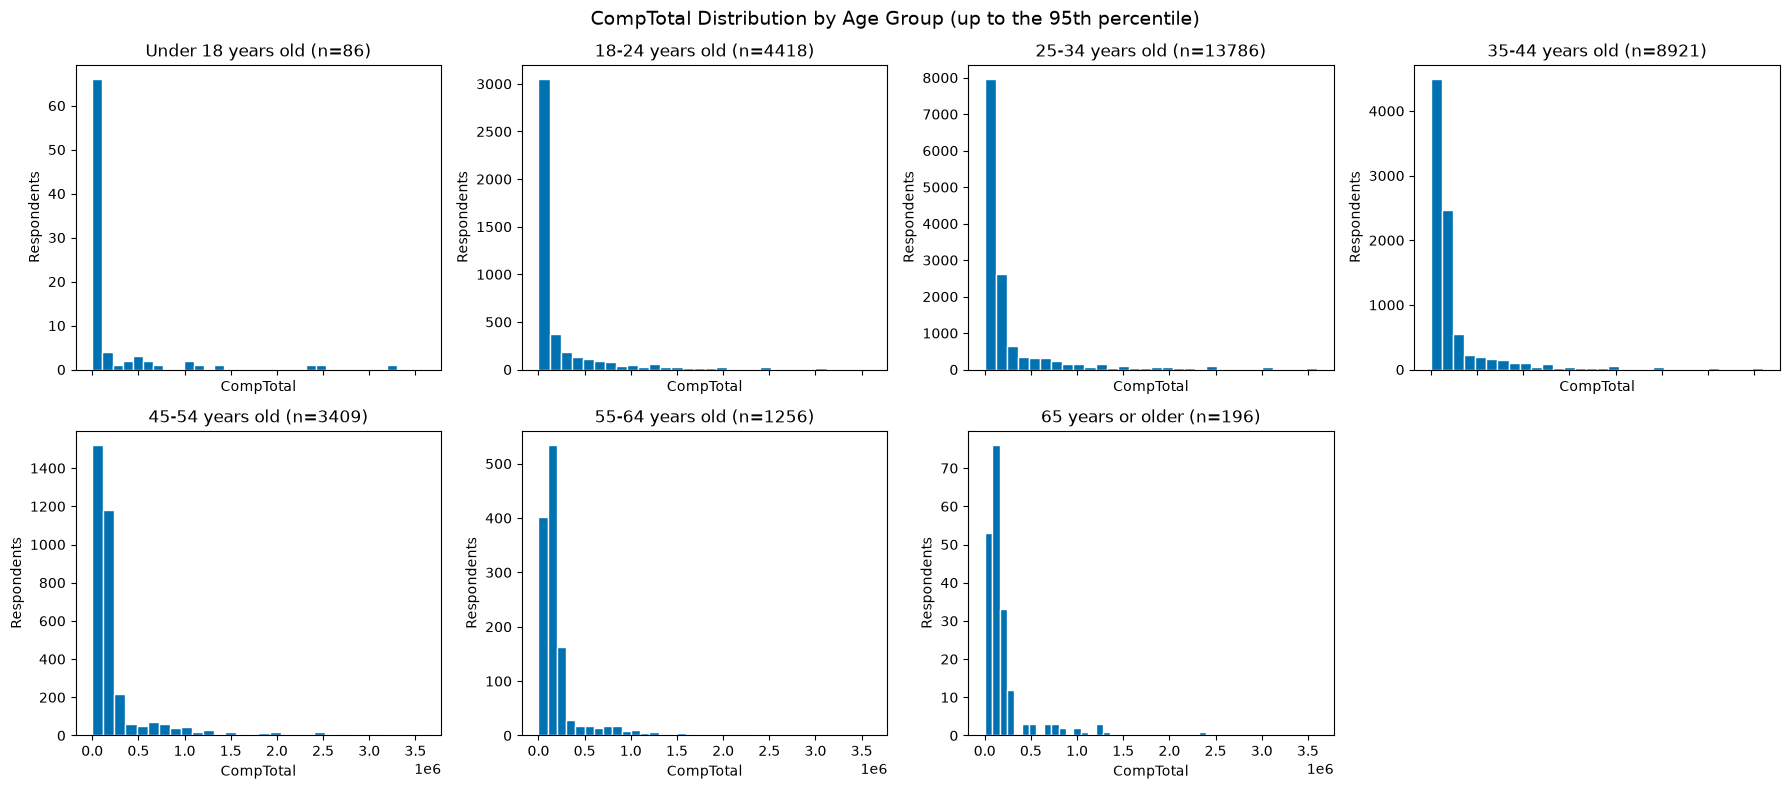

In [12]:
## Write your code here
## Write your code here
age_order = ["Under 18 years old", "18-24 years old", "25-34 years old", "35-44 years old",
             "45-54 years old", "55-64 years old", "65 years or older"]

df_ac = pd.read_sql_query("SELECT Age, CompTotal FROM main WHERE CompTotal IS NOT NULL", conn)
df_ac = df_ac[df_ac["Age"].isin(age_order)]

cap = df_ac["CompTotal"].quantile(0.95)
df_ac = df_ac[df_ac["CompTotal"] <= cap]

fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True)
axes = axes.flatten()
for ax, age in zip(axes, age_order):
    data = df_ac.loc[df_ac["Age"] == age, "CompTotal"]
    ax.hist(data, bins=30, color="#0072B2", edgecolor="white")
    ax.set_title(f"{age} (n={len(data)})")
    ax.set_xlabel("CompTotal")
    ax.set_ylabel("Respondents")
axes[-1].axis("off")   # 7 groups, so the 8th panel stays empty
fig.suptitle("CompTotal Distribution by Age Group (up to the 95th percentile)", fontsize=14)
plt.tight_layout()
plt.show()

**2.2 Histogram of TimeSearching for Different Age Groups**


Objective: Use histograms to explore the distribution of `TimeSearching` (time spent searching for information) for respondents across different age groups.


TimeSearching       Less than 15 minutes a day  15-30 minutes a day  \
Age                                                                   
Under 18 years old                         9.7                 25.0   
18-24 years old                            5.3                 22.1   
25-34 years old                            8.3                 26.4   
35-44 years old                           11.4                 28.6   
45-54 years old                           11.8                 30.1   
55-64 years old                           12.9                 33.2   
65 years or older                         15.3                 28.8   

TimeSearching       30-60 minutes a day  60-120 minutes a day  \
Age                                                             
Under 18 years old                 38.9                  19.4   
18-24 years old                    38.7                  23.9   
25-34 years old                    38.9                  18.6   
35-44 years old                    

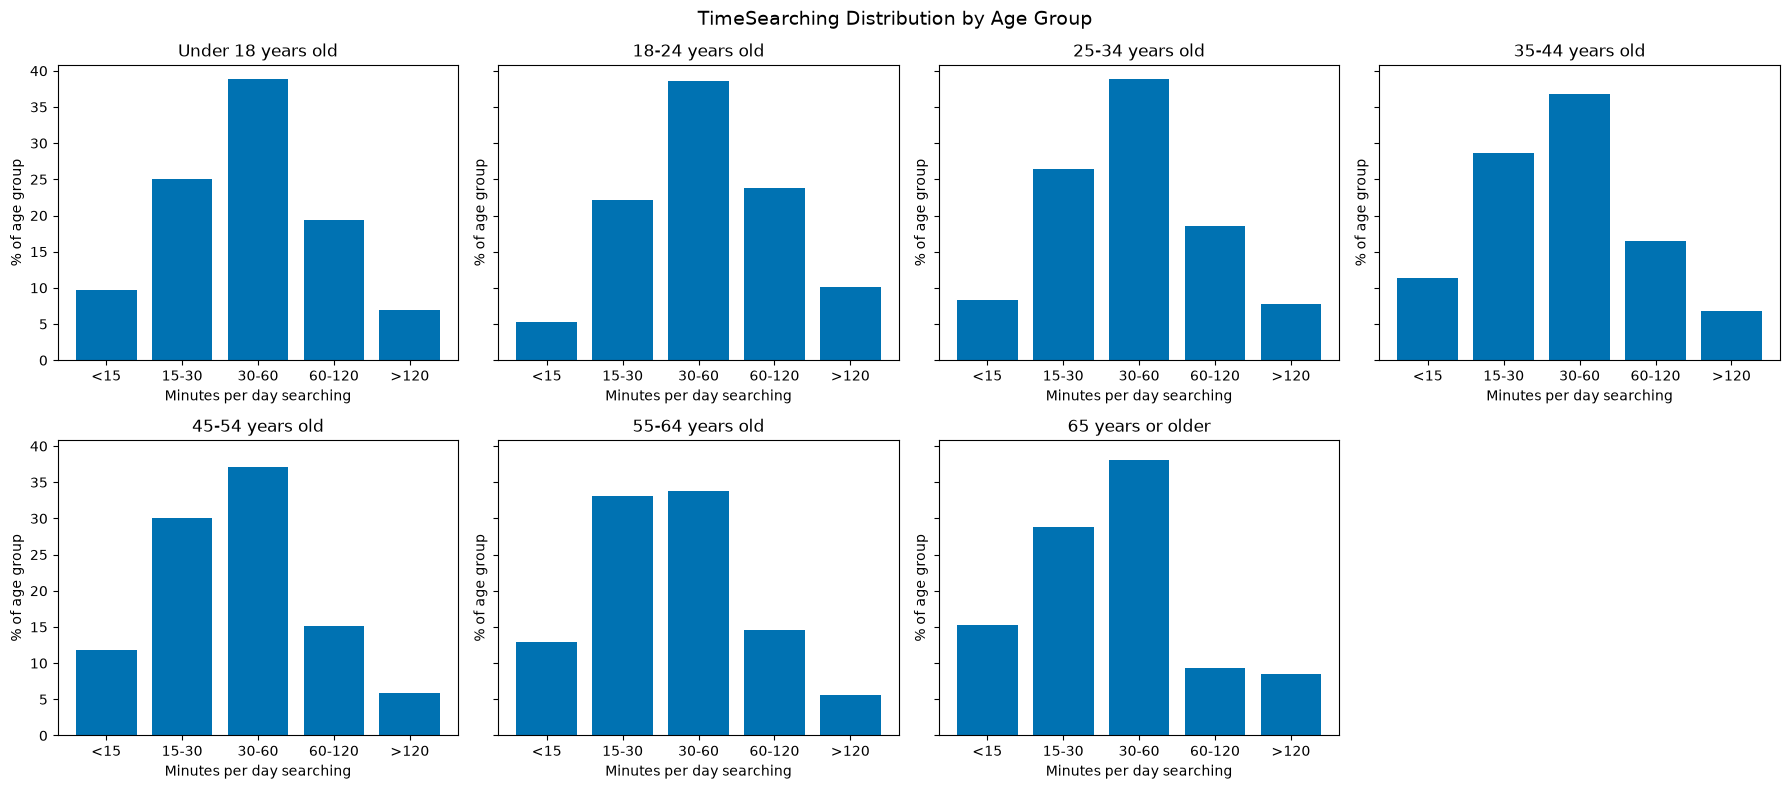

In [13]:
## Write your code here
## Write your code here
time_order = ["Less than 15 minutes a day", "15-30 minutes a day", "30-60 minutes a day",
              "60-120 minutes a day", "Over 120 minutes a day"]

df_ts = pd.read_sql_query("SELECT Age, TimeSearching FROM main WHERE TimeSearching IS NOT NULL", conn)
df_ts = df_ts[df_ts["Age"].isin(age_order)]

pct = (pd.crosstab(df_ts["Age"], df_ts["TimeSearching"], normalize="index") * 100)
pct = pct.reindex(index=age_order, columns=time_order)
print(pct.round(1))

fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=True)
axes = axes.flatten()
for ax, age in zip(axes, age_order):
    ax.bar(range(len(time_order)), pct.loc[age].values, color="#0072B2")
    ax.set_title(age)
    ax.set_xticks(range(len(time_order)))
    ax.set_xticklabels(["<15", "15-30", "30-60", "60-120", ">120"])
    ax.set_xlabel("Minutes per day searching")
    ax.set_ylabel("% of age group")
axes[-1].axis("off")
fig.suptitle("TimeSearching Distribution by Age Group", fontsize=14)
plt.tight_layout()
plt.show()

### 3. Visualizing the Composition of Data


**3.1 Histogram of Most Desired Databases (`DatabaseWantToWorkWith`)**


Objective: Visualize the most desired databases for future learning using a histogram of the top 5 databases.


DatabaseWantToWorkWith
PostgreSQL    24005
SQLite        13489
MySQL         12269
MongoDB       10982
Redis         10847
Name: count, dtype: int64

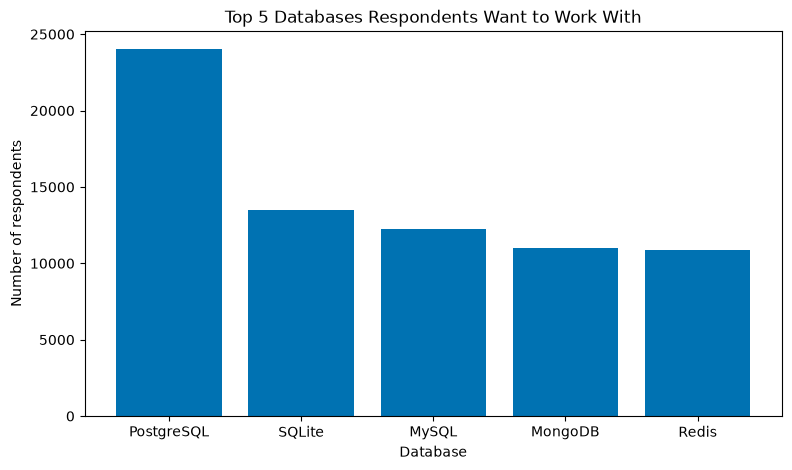

In [14]:
## Write your code here
## Write your code here
df_db = pd.read_sql_query("SELECT DatabaseWantToWorkWith FROM main WHERE DatabaseWantToWorkWith IS NOT NULL", conn)

db_counts = df_db["DatabaseWantToWorkWith"].str.split(";").explode().str.strip().value_counts()
top5 = db_counts.head(5)
print(top5)

plt.figure(figsize=(9, 5))
plt.bar(top5.index, top5.values, color="#0072B2")
plt.title("Top 5 Databases Respondents Want to Work With")
plt.xlabel("Database")
plt.ylabel("Number of respondents")
plt.show()

**3.2 Histogram of Preferred Work Locations (`RemoteWork`)**


Objective: Use a histogram to explore the distribution of preferred work arrangements (`remote work`).


RemoteWork
Hybrid (some remote, some in-person)    23015
Remote                                  20831
In-person                               10960
Name: count, dtype: int64

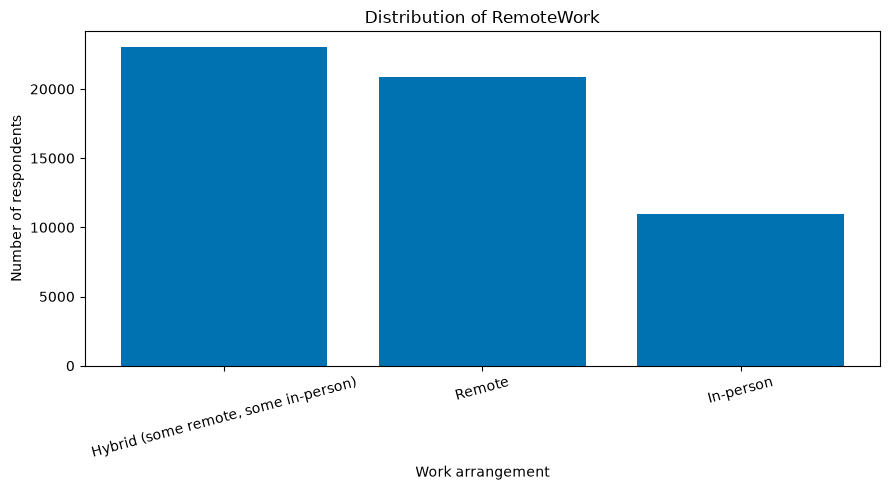

In [15]:
## Write your code here
## Write your code here
df_rw = pd.read_sql_query("SELECT RemoteWork FROM main WHERE RemoteWork IS NOT NULL", conn)
rw_counts = df_rw["RemoteWork"].value_counts()
print(rw_counts)

plt.figure(figsize=(9, 5))
plt.bar(rw_counts.index, rw_counts.values, color="#0072B2")
plt.title("Distribution of RemoteWork")
plt.xlabel("Work arrangement")
plt.ylabel("Number of respondents")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### 4. Visualizing Comparison of Data


**4.1 Histogram of Median CompTotal for Ages 45 to 60**


Objective: Plot the histogram for `CompTotal` within the age group 45 to 60 to analyze compensation distribution among mid-career respondents.


Age
45-54 years old    130000.0
55-64 years old    135000.0
Name: CompTotal, dtype: float64

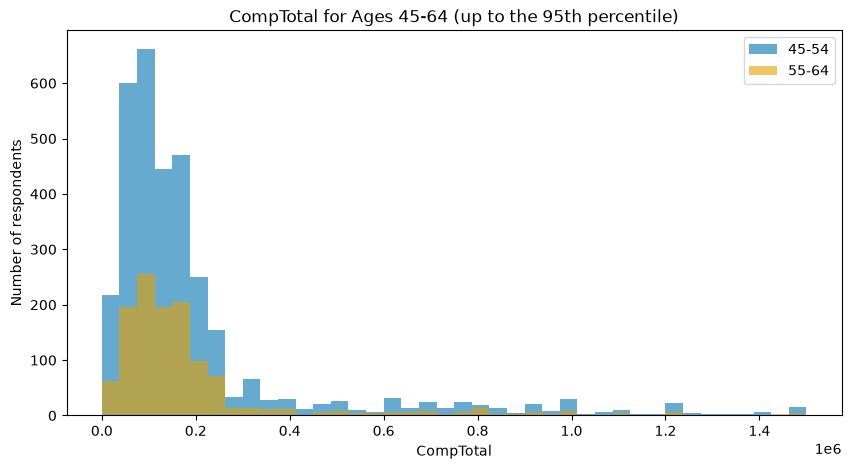

In [16]:
## Write your code here
## Write your code here
df_mid = pd.read_sql_query(
    "SELECT Age, CompTotal FROM main WHERE CompTotal IS NOT NULL AND Age IN ('45-54 years old', '55-64 years old')",
    conn)
print(df_mid.groupby("Age")["CompTotal"].median())

cap = df_mid["CompTotal"].quantile(0.95)
d = df_mid[df_mid["CompTotal"] <= cap]

plt.figure(figsize=(10, 5))
plt.hist(d.loc[d["Age"] == "45-54 years old", "CompTotal"], bins=40, alpha=0.6, label="45-54", color="#0072B2")
plt.hist(d.loc[d["Age"] == "55-64 years old", "CompTotal"], bins=40, alpha=0.6, label="55-64", color="#E69F00")
plt.title("CompTotal for Ages 45-64 (up to the 95th percentile)")
plt.xlabel("CompTotal")
plt.ylabel("Number of respondents")
plt.legend()
plt.show()

**4.2 Histogram of Job Satisfaction (`JobSat`) by YearsCodePro**


Objective: Plot the histogram for `JobSat` scores based on respondents' years of professional coding experience.


             count  median  mean
Experience                      
0-2 years     4106     7.0  6.69
3-5 years     6143     7.0  6.71
6-10 years    7737     7.0  6.94
11-20 years   6899     8.0  7.12
20+ years     3471     8.0  7.35

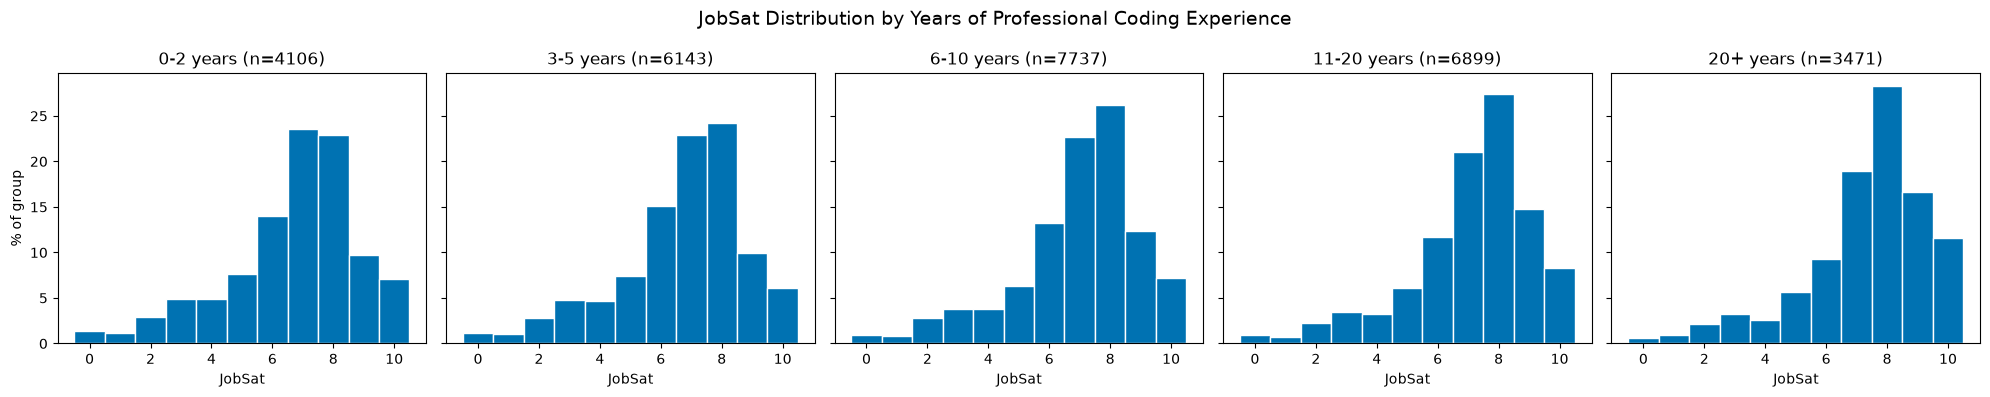

In [17]:
## Write your code here
## Write your code here
df_js = pd.read_sql_query(
    "SELECT YearsCodePro, JobSat FROM main WHERE JobSat IS NOT NULL AND YearsCodePro IS NOT NULL", conn)

df_js["Years"] = pd.to_numeric(
    df_js["YearsCodePro"].replace({"Less than 1 year": 0.5, "More than 50 years": 50}), errors="coerce")
df_js["JobSat"] = pd.to_numeric(df_js["JobSat"], errors="coerce")
df_js = df_js.dropna(subset=["Years", "JobSat"])

bands = ["0-2 years", "3-5 years", "6-10 years", "11-20 years", "20+ years"]
df_js["Experience"] = pd.cut(df_js["Years"], bins=[-1, 2, 5, 10, 20, 100], labels=bands)
print(df_js.groupby("Experience", observed=True)["JobSat"].agg(["count", "median", "mean"]).round(2))

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharex=True, sharey=True)
for ax, band in zip(axes, bands):
    data = df_js.loc[df_js["Experience"] == band, "JobSat"]
    ax.hist(data, bins=11, range=(-0.5, 10.5), weights=[100 / len(data)] * len(data),
            color="#0072B2", edgecolor="white")
    ax.set_title(f"{band} (n={len(data)})")
    ax.set_xlabel("JobSat")
axes[0].set_ylabel("% of group")
fig.suptitle("JobSat Distribution by Years of Professional Coding Experience", fontsize=14)
plt.tight_layout()
plt.show()

### Final step: Close the database connection


Once you've completed the lab, make sure to close the connection to the SQLite database:



In [18]:
conn.close()

### Summary


In this lab, you used histograms to visualize various aspects of the dataset, focusing on:

- Distribution of compensation, coding experience, and work hours.

- Relationships in compensation across age groups and work status.

- Composition of data by desired databases and work environments.

- Comparisons of job satisfaction across years of experience.

Histograms helped reveal patterns and distributions in the data, enhancing your understanding of developer demographics and preferences.


## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


Copyright © IBM Corporation. All rights reserved.
